In [1]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt


In [2]:
data = pd.read_csv("train.csv")
data['date'] = pd.to_datetime(data['date'])

df = data[(data['store'] == 1) & (data['item'] == 1)].copy()
df = df.sort_values('date')


In [3]:
df['lag_1'] = df['sales'].shift(1)
df['lag_7'] = df['sales'].shift(7)
df['lag_30'] = df['sales'].shift(30)

df = df.dropna()


In [4]:
split_index = int(len(df) * 0.8)

train = df.iloc[:split_index]
valid = df.iloc[split_index:]

X_train = train[['lag_1', 'lag_7', 'lag_30']]
y_train = train['sales']

X_valid = valid[['lag_1', 'lag_7', 'lag_30']]
y_valid = valid['sales']


In [5]:
model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_valid)


In [6]:
mae = mean_absolute_error(y_valid, predictions)
rmse = np.sqrt(mean_squared_error(y_valid, predictions))

print("Linear Regression MAE:", mae)
print("Linear Regression RMSE:", rmse)


Linear Regression MAE: 4.572483577948009
Linear Regression RMSE: 5.725100446177144


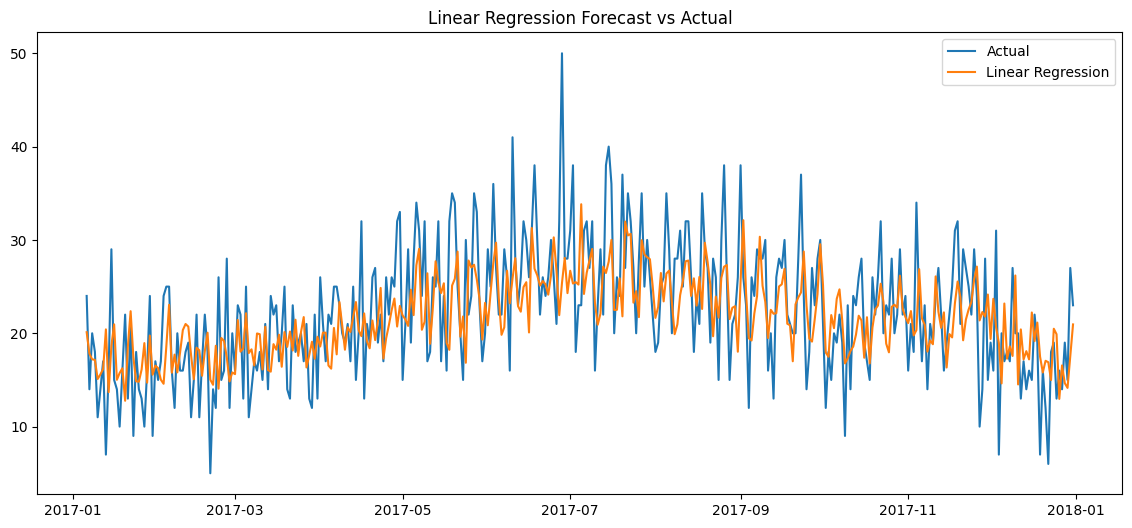

In [7]:
plt.figure(figsize=(14,6))
plt.plot(valid['date'], y_valid, label='Actual')
plt.plot(valid['date'], predictions, label='Linear Regression')
plt.legend()
plt.title("Linear Regression Forecast vs Actual")
plt.show()
